In [7]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# 2010 se 2026 tak ki प्रमुख फिल्में aur unke Primary Genres
# Har row ek transaction hai jisme Movie Name + Genres shaamil hain
movies_genre_data = [
    # 2010 - 2015
    ['Dabangg (2010)', 'Action', 'Comedy'],
    ['Singham (2011)', 'Action', 'Drama'],
    ['Barfi! (2012)', 'Comedy', 'Drama', 'Romance'],
    ['Yeh Jawaani Hai Deewani (2013)', 'Romance', 'Comedy', 'Drama'],
    ['Dhoom 3 (2013)', 'Action', 'Thriller'],
    ['PK (2014)', 'Comedy', 'Drama'],
    ['Bajrangi Bhaijaan (2015)', 'Drama', 'Action'],
    ['Baahubali: The Beginning (2015)', 'Action', 'Drama', 'Fantasy'],

    # 2016 - 2020
    ['Dangal (2016)', 'Biography', 'Drama', 'Sports'],
    ['Baahubali 2: The Conclusion (2017)', 'Action', 'Drama', 'Fantasy'],
    ['Sanju (2018)', 'Biography', 'Drama'],
    ['Andhadhun (2018)', 'Thriller', 'Comedy', 'Crime'],
    ['KGF: Chapter 1 (2018)', 'Action', 'Drama', 'Crime'],
    ['War (2019)', 'Action', 'Thriller'],
    ['Tanhaji (2020)', 'Action', 'Biography', 'Drama'],

    # 2021 - 2024
    ['Pushpa: The Rise (2021)', 'Action', 'Crime', 'Drama'],
    ['RRR (2022)', 'Action', 'Drama'],
    ['KGF: Chapter 2 (2022)', 'Action', 'Crime', 'Drama'],
    ['Kantara (2022)', 'Action', 'Drama', 'Thriller'],
    ['Pathaan (2023)', 'Action', 'Thriller'],
    ['Jawan (2023)', 'Action', 'Thriller', 'Drama'],
    ['Animal (2023)', 'Action', 'Crime', 'Drama'],
    ['12th Fail (2023)', 'Biography', 'Drama'],
    ['Kalki 2898 AD (2024)', 'Action', 'Sci-Fi', 'Fantasy'],
    ['Stree 2 (2024)', 'Comedy', 'Horror'],
    ['Pushpa 2: The Rule (2024)', 'Action', 'Crime', 'Drama'],

    # 2025 - 2026
    ['War 2 (2025)', 'Action', 'Thriller'],
    ['Toxic (2025)', 'Action', 'Crime', 'Drama'],
    ['Spirit (2026)', 'Action', 'Crime', 'Drama'],
    ['Kantara: Chapter 1 (2026)', 'Action', 'Drama', 'Thriller']
]

# Case 1: Agar sirf GENRES ke beech Association Rules nikalne hain
genre_transactions = [
    [item for item in row if '(' not in item] 
    for row in movies_genre_data
]

# One-hot encoding
te = TransactionEncoder()
te_ary = te.fit(genre_transactions).transform(genre_transactions)
df_genres = pd.DataFrame(te_ary, columns=te.columns_)

# Apriori (min_support = 20%)
frequent_itemsets = apriori(df_genres, min_support=0.20, use_colnames=True)

# Rules (min_confidence = 50%)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

# View top rules sorted by Lift
print("--- Top Genre Association Rules ---")
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]

--- Top Genre Association Rules ---


,antecedents,consequents,support,confidence,lift
0,frozenset({Crime}),frozenset({Action}),0.233333,0.875000,1.193182
1,frozenset({Action}),frozenset({Drama}),0.533333,0.727273,0.991736
2,frozenset({Drama}),frozenset({Action}),0.533333,0.727273,0.991736
3,frozenset({Thriller}),frozenset({Action}),0.233333,0.875000,1.193182
4,frozenset({Crime}),frozenset({Drama}),0.233333,0.875000,1.193182
5,"frozenset({Crime, Action})",frozenset({Drama}),0.233333,1.000000,1.363636
6,"frozenset({Crime, Drama})",frozenset({Action}),0.233333,1.000000,1.363636
7,frozenset({Crime}),"frozenset({Action, Drama})",0.233333,0.875000,1.640625


In [11]:
df = pd.read_csv(r"C:\Users\dell\Downloads\movies_data.csv")
df.head()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,#Gadhvi (He thought he was Gandhi),2019,109,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
1,#Yaaram,2019,110,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
2,...Aur Pyaar Ho Gaya,1997,147,"Comedy, Drama, Musical",4.7,827,Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor
3,...Yahaan,2005,142,"Drama, Romance, War",7.4,1086,Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma
4,?: A Question Mark,2012,82,"Horror, Mystery, Thriller",5.6,326,Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia


In [9]:
df.shape

(5659, 10)

In [12]:

df.isnull().sum()

Name        0
Year        0
Duration    0
Genre       0
Rating      0
Votes       0
Director    0
Actor 1     0
Actor 2     0
Actor 3     0
dtype: int64

In [23]:
# Step 1: Comma-separated genres ko list me split karein
transactions = df['Genre'].dropna().apply(lambda x: [g.strip() for g in x.split(',')]).tolist()

In [24]:
transactions[:3]

[['Drama'], ['Comedy', 'Romance'], ['Comedy', 'Drama', 'Musical']]

In [25]:
# Step 2: One-Hot Encoding format me convert karein
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

# Step 3: Frequent Itemsets nikaalein (min_support = 5% ya 0.05)
frequent_itemsets = apriori(df_encoded, min_support=0.05, use_colnames=True)

# Step 4: Association Rules generate karein (min_confidence = 30%)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.3)

# Step 5: Top rules ko Lift ke hisab se sort karke dekhein
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values(by='lift', ascending=False).head(10)

,antecedents,consequents,support,confidence,lift
9,"frozenset({Action, Drama})",frozenset({Crime}),0.058844,0.335347,2.168836
10,frozenset({Crime}),"frozenset({Action, Drama})",0.058844,0.380571,2.168836
1,frozenset({Action}),frozenset({Crime}),0.090299,0.303084,1.960176
0,frozenset({Crime}),frozenset({Action}),0.090299,0.584000,1.960176
8,"frozenset({Crime, Drama})",frozenset({Action}),0.058844,0.568259,1.907343
5,frozenset({Family}),frozenset({Drama}),0.058844,0.800481,1.193341
4,frozenset({Crime}),frozenset({Drama}),0.103552,0.669714,0.998397
7,"frozenset({Crime, Action})",frozenset({Drama}),0.058844,0.651663,0.971487
6,frozenset({Romance}),frozenset({Drama}),0.158332,0.649275,0.967927
2,frozenset({Action}),frozenset({Drama}),0.175473,0.588968,0.878022


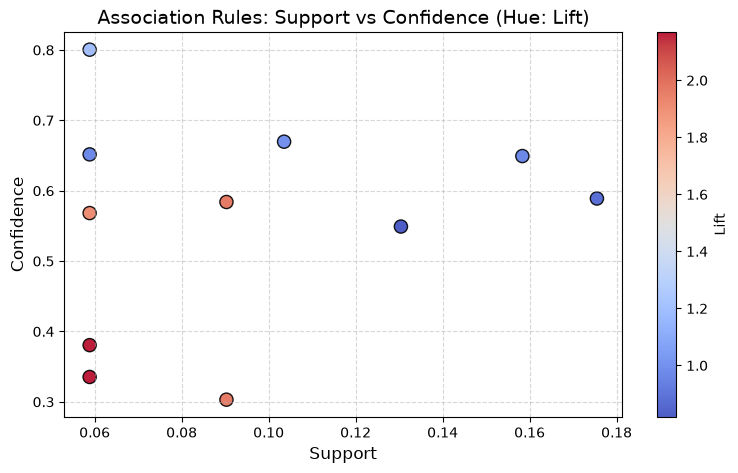

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
scatter = plt.scatter(
    rules['support'], 
    rules['confidence'], 
    c=rules['lift'], 
    cmap='coolwarm', 
    alpha=0.9, 
    s=90, 
    edgecolors='black'
)

plt.colorbar(scatter, label='Lift')
plt.xlabel('Support', fontsize=12)
plt.ylabel('Confidence', fontsize=12)
plt.title('Association Rules: Support vs Confidence (Hue: Lift)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

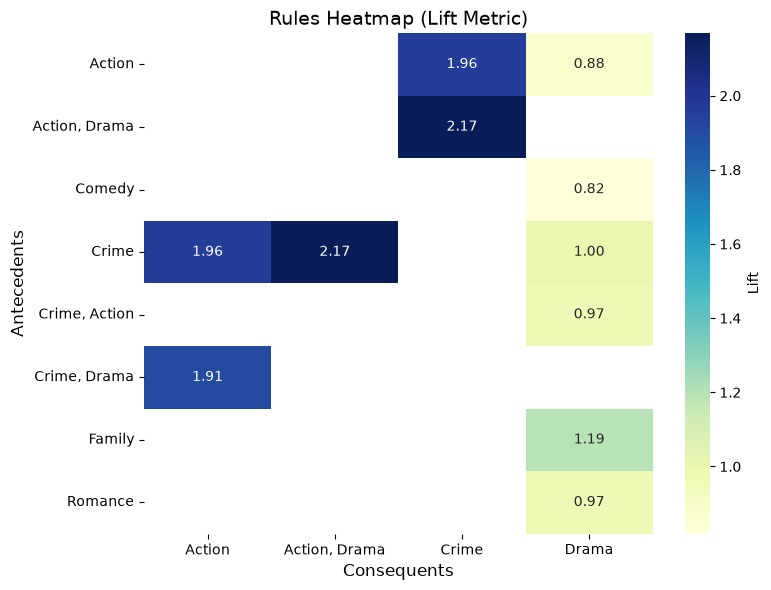

In [27]:
# Frozensets ko string me convert karein taaki clean labels banein
rules['antecedent_str'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequent_str'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))

# Pivot table banayein
pivot_table = rules.pivot(index='antecedent_str', columns='consequent_str', values='lift')

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap='YlGnBu', cbar_kws={'label': 'Lift'})
plt.title('Rules Heatmap (Lift Metric)', fontsize=14)
plt.xlabel('Consequents', fontsize=12)
plt.ylabel('Antecedents', fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\dell\AppData\Local\Temp\ipykernel_1568\4218361009.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_rules, x='lift', y='rule_label', palette='viridis')


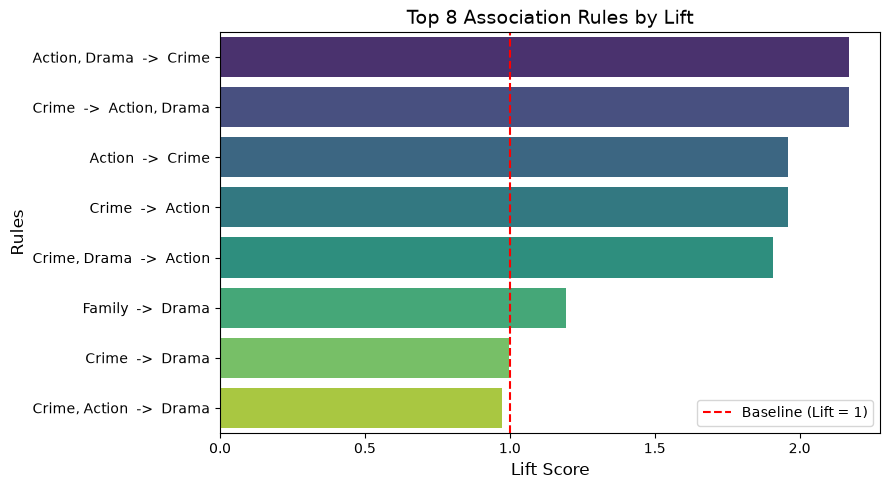

In [28]:
top_rules = rules.sort_values(by='lift', ascending=False).head(8).copy()
top_rules['rule_label'] = top_rules['antecedent_str'] + '  ->  ' + top_rules['consequent_str']

plt.figure(figsize=(9, 5))
sns.barplot(data=top_rules, x='lift', y='rule_label', palette='viridis')
plt.title('Top 8 Association Rules by Lift', fontsize=14)
plt.xlabel('Lift Score', fontsize=12)
plt.ylabel('Rules', fontsize=12)
plt.axvline(1, color='red', linestyle='--', label='Baseline (Lift = 1)')
plt.legend()
plt.tight_layout()
plt.show()

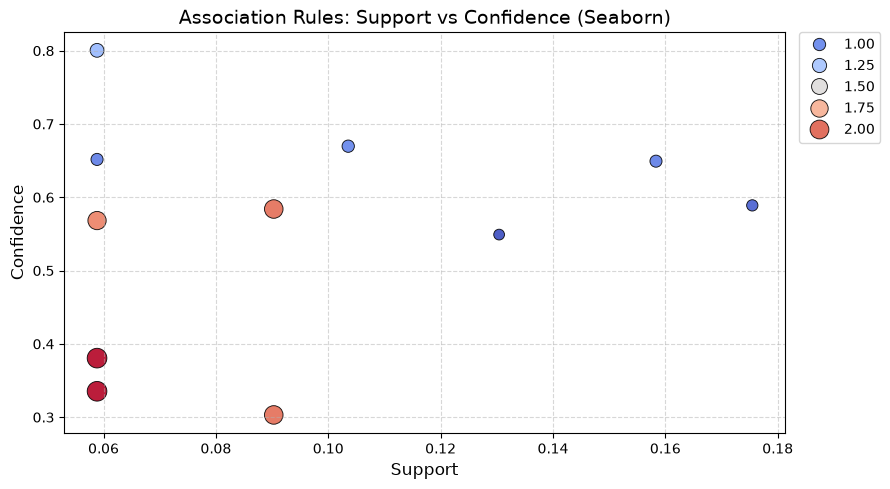

In [38]:
plt.figure(figsize=(9, 5))

# Seaborn scatterplot with hue (lift) and size
sns.scatterplot(
    data=rules,
    x='support',
    y='confidence',
    hue='lift',
    palette='coolwarm',
    size='lift',
    sizes=(60, 200),
    alpha=0.9,
    edgecolor='black'
)

plt.title('Association Rules: Support vs Confidence (Seaborn)', fontsize=14)
plt.xlabel('Support', fontsize=12)
plt.ylabel('Confidence', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()

In [39]:
for item in range(6):
    if item == 3: break
    print(item)
else:
    print("Finally finished!")

0
1
2
